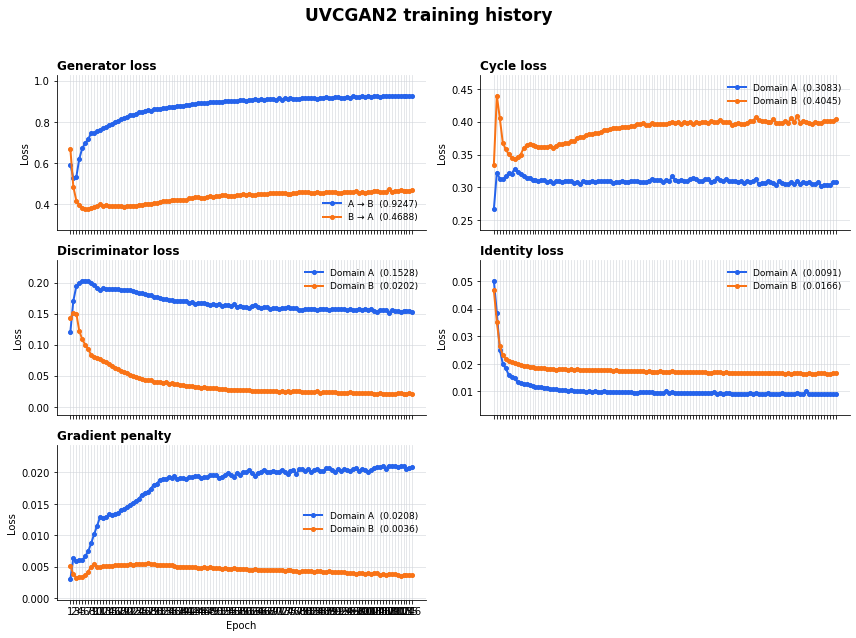

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

history_path = "outdir/crystalSmall/crystalSmall/model_m(uvcgan2)_d(basic)_g(vit-modnet)_uvcgan2-bn_(False:10.0:0.01:5e-05:bs32)/history.csv"
df = pd.read_csv(history_path).sort_values("epoch")

panels = [
    ("Generator loss", ("gen_ab", "gen_ba"), ("A → B", "B → A")),
    ("Cycle loss", ("cycle_a", "cycle_b"), ("Domain A", "Domain B")),
    ("Discriminator loss", ("disc_a", "disc_b"), ("Domain A", "Domain B")),
    ("Identity loss", ("idt_a", "idt_b"), ("Domain A", "Domain B")),
    ("Gradient penalty", ("gp_a", "gp_b"), ("Domain A", "Domain B")),
]
colors = ("#2563eb", "#f97316")

fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
fig.suptitle("UVCGAN2 training history", fontsize=17, fontweight="bold")

for ax, (title, columns, labels) in zip(axes.flat, panels):
    for column, label, color in zip(columns, labels, colors):
        final_value = df[column].iloc[-1]
        ax.plot(
            df["epoch"], df[column],
            color=color, marker="o", markersize=4, linewidth=2,
            label=f"{label}  ({final_value:.4f})",
        )
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_ylabel("Loss")
    ax.grid(True, color="#d1d5db", linewidth=0.8, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)
    ax.set_xticks(df["epoch"])
    ax.margins(x=0.04, y=0.18)

axes[2, 1].set_visible(False)
for ax in axes[2, :]:
    ax.set_xlabel("Epoch")

fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

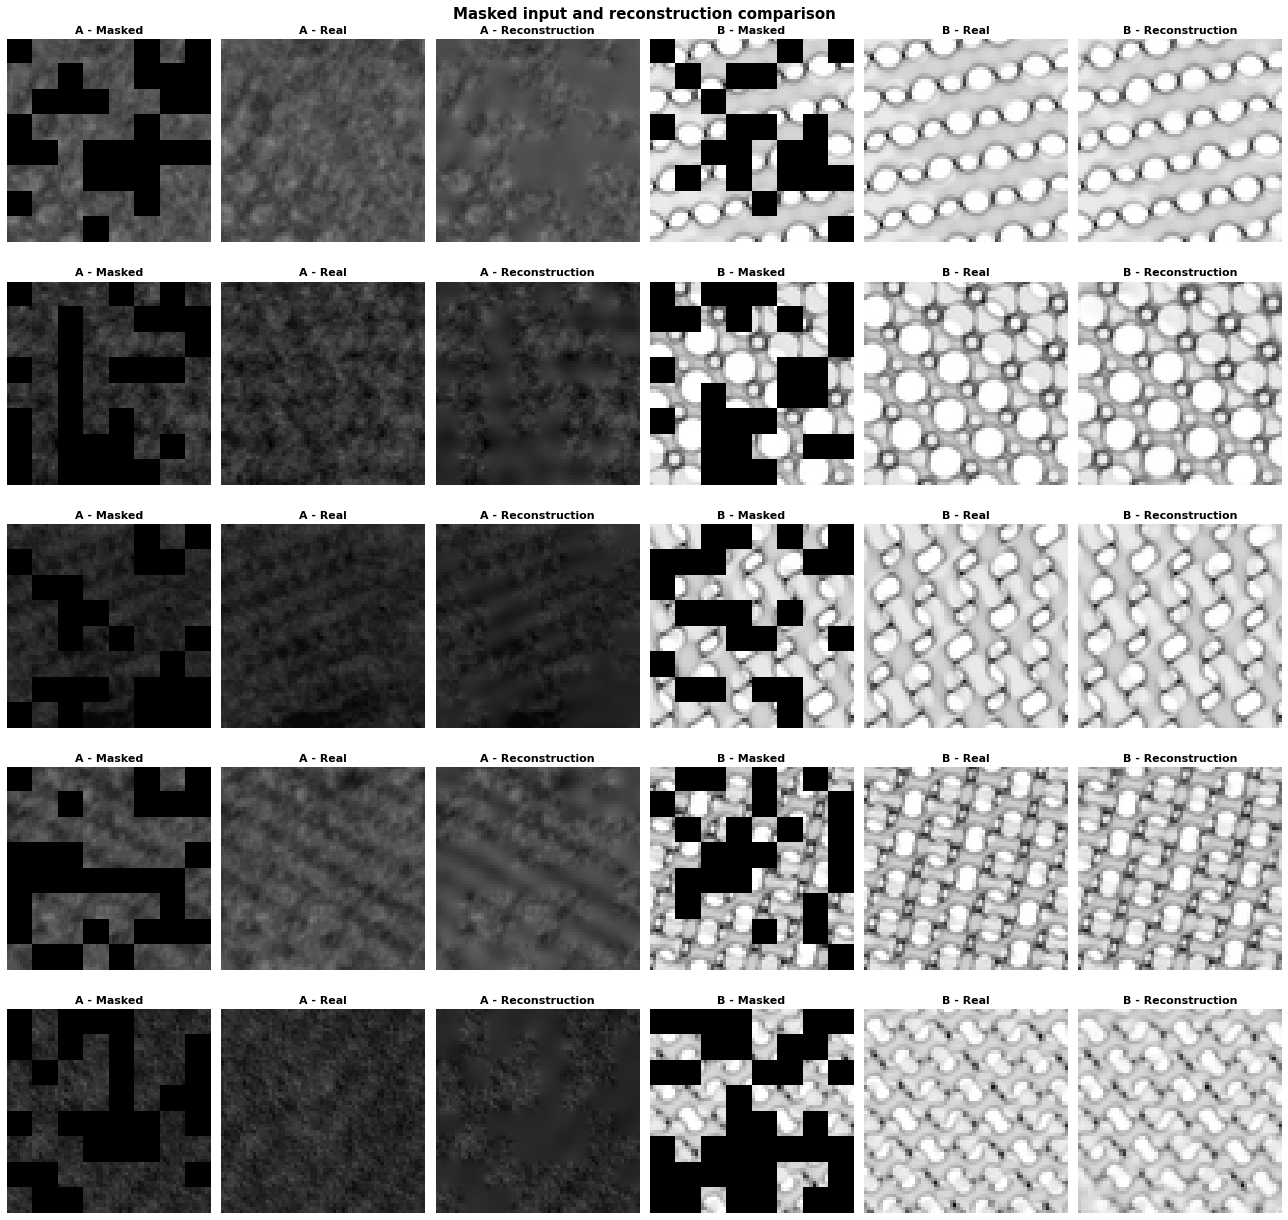

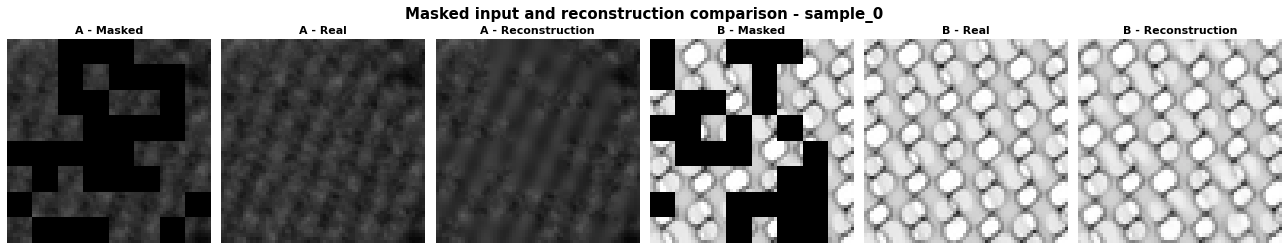

In [1]:
from pathlib import Path
from PIL import Image
import random
import matplotlib.pyplot as plt

evals_dir = Path("outdir/crystalSmall/model100epochs/evals/final/images_eval-val")
image_types = ["masked_a", "real_a", "reco_a", "masked_b", "real_b", "reco_b"]
titles = ["A - Masked", "A - Real", "A - Reconstruction",
          "B - Masked", "B - Real", "B - Reconstruction"]

if not evals_dir.exists():
    print(f"Evaluation folder not found: {evals_dir.resolve()}")
else:
    sample_ids_by_type = [
        {path.stem for path in (evals_dir / image_type).glob("sample_*") if path.is_file()}
        for image_type in image_types
    ]
    common_sample_ids = set.intersection(*sample_ids_by_type)

    if not common_sample_ids:
        print(f"No sample is present for all six image types in {evals_dir.resolve()}")
    else:
        sample_ids = random.sample(
            list(common_sample_ids),
            k=min(5, len(common_sample_ids)),
        )

        fig, axes = plt.subplots(
            len(sample_ids), len(image_types),
            figsize=(18, 3.5 * len(sample_ids)),
            squeeze=False,
        )
        fig.suptitle("Masked input and reconstruction comparison",
                     fontsize=15, fontweight="bold")

        for row, sample_id in enumerate(sample_ids):
            for col, (image_type, title) in enumerate(zip(image_types, titles)):
                image_path = evals_dir / image_type / f"{sample_id}.png"
                with Image.open(image_path) as image:
                    axes[row, col].imshow(image.copy())

                axes[row, col].set_title(title, fontsize=11, fontweight="bold")
                axes[row, col].axis("off")

            axes[row, 0].set_ylabel(sample_id, fontsize=10)

        fig.tight_layout()
        plt.show()

evals_dir = Path("outdir/crystalSmall/model100epochs/evals/final/images_eval-val")
image_types = ["masked_a", "real_a", "reco_a", "masked_b", "real_b", "reco_b"]

if not evals_dir.exists():
    print(f"Evaluation folder not found: {evals_dir.resolve()}")
else:
    sample_ids_by_type = [
        {path.stem for path in (evals_dir / image_type).glob("sample_*") if path.is_file()}
        for image_type in image_types
    ]
    common_sample_ids = set.intersection(*sample_ids_by_type)

    if not common_sample_ids:
        print(f"No sample is present for all six image types in {evals_dir.resolve()}")
    else:
        sample_id = min(common_sample_ids, key=lambda value: int(value.rsplit("_", 1)[-1]))
        titles = ["A - Masked", "A - Real", "A - Reconstruction",
                  "B - Masked", "B - Real", "B - Reconstruction"]

        fig, axes = plt.subplots(1, len(image_types), figsize=(18, 3.5))
        fig.suptitle(f"Masked input and reconstruction comparison - {sample_id}",
                     fontsize=15, fontweight="bold")

        for ax, image_type, title in zip(axes, image_types, titles):
            image_path = evals_dir / image_type / f"{sample_id}.png"
            with Image.open(image_path) as image:
                ax.imshow(image.copy())
            ax.set_title(title, fontsize=11, fontweight="bold")
            ax.axis("off")

        fig.tight_layout()
        plt.show()

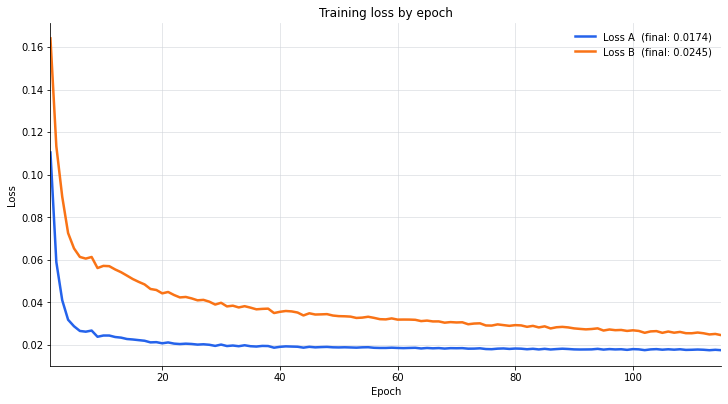

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/home/jan/uvcgan2/uvcgan2/outdir/crystalSmall/model100epochs/history.csv").sort_values("epoch")
window = 1

colors = {"loss_a": "#2563eb", "loss_b": "#f97316"}

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")

for column, label in [("loss_a", "Loss A"), ("loss_b", "Loss B")]:
    color = colors[column]
    ax.plot(df["epoch"], df[column], color=color, alpha=0.22, linewidth=1)
    smooth = df[column].rolling(window, min_periods=1).mean()
    ax.plot(
        df["epoch"], smooth, color=color, linewidth=2.5,
        label=f"{label}  (final: {df[column].iloc[-1]:.4f})",
    )

ax.set(
    title="Training loss by epoch",
    xlabel="Epoch",
    ylabel="Loss",
    xlim=(df["epoch"].min(), df["epoch"].max()),
)
ax.grid(True, color="#d1d5db", linewidth=0.8, alpha=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()